# Mathematics of the Logistic Map and Chaos

## 1. The logistic map

The discrete-time logistic map is

$$x_{n+1} = r\,x_n\,(1 - x_n), \qquad x_n \in [0,1], \qquad r \in [0,4]. \tag{1}$$

It is the discrete analogue of the logistic differential equation, and it is the equation Roughgarden (1971) obtains when the locus is fixed for one allele:

$$\Delta N = r\,N\,\frac{K - N}{K}.$$

Setting $x_n = N_n / K$ and using $N_{n+1} = N_n + \Delta N_n$ gives

$$x_{n+1} = x_n + r\,x_n\,(1 - x_n) = (1+r)\,x_n - r\,x_n^{2},$$

which is a logistic map in the general form $x_{n+1} = a\,x_n - b\,x_n^{2}$. The standard form (1) is recovered by rescaling $x$ and $r$.

## 2. Fixed points

A fixed point $x^{*}$ satisfies $x^{*} = r\,x^{*}(1 - x^{*})$. The two solutions are

$$x^{*}_0 = 0, \qquad x^{*}_1 = 1 - \frac{1}{r}. \tag{2}$$

The non-trivial fixed point $x^{*}_1$ is biologically meaningful only when $r > 1$, since $x^{*}_1 \in (0,1)$ requires $r > 1$.

## 3. Linear stability analysis

Let $f(x) = r\,x(1-x)$. The derivative is

$$f'(x) = r\,(1 - 2x).$$

A fixed point $x^{*}$ is **asymptotically stable** if $|f'(x^{*})| < 1$.

- At $x^{*}_0 = 0$: $f'(0) = r$, so the origin is stable for $r < 1$.
- At $x^{*}_1 = 1 - 1/r$:

$$f'(x^{*}_1) = r\left(1 - 2\left(1 - \frac{1}{r}\right)\right) = 2 - r.$$

So $x^{*}_1$ is stable when $|2 - r| < 1$, i.e. when

$$1 < r < 3. \tag{3}$$

At $r = 3$ the derivative equals $-1$, and the fixed point loses stability through a **period-doubling bifurcation**.

## 4. Period doubling and the Feigenbaum cascade

For $r > 3$, the map settles into a stable **2-cycle** $\{x_1, x_2\}$ satisfying

$$x_2 = r\,x_1(1 - x_1), \qquad x_1 = r\,x_2(1 - x_2),$$

which can be solved by considering the second iterate $f^{(2)}(x) = f(f(x))$. The 2-cycle is stable for $3 < r < 1 + \sqrt{6} \approx 3.449$.

As $r$ increases further, the 2-cycle bifurcates into a 4-cycle, then an 8-cycle, and so on. The bifurcation points $r_k$ converge geometrically to the accumulation point

$$r_\infty \approx 3.5699456\ldots$$

Beyond $r_\infty$ the dynamics become **chaotic** on intervals, punctuated by periodic windows.



## 5. Cobweb diagram

The cobweb construction visualizes the iteration geometrically:

1. Start at $(x_0, 0)$.
2. Move vertically to the parabola: $(x_0, f(x_0))$.
3. Move horizontally to the diagonal: $(f(x_0), f(x_0))$.
4. Repeat with $x_1 = f(x_0)$.

The resulting staircase shows the long-term behavior:

- **Stable fixed point** ($r < 3$): the staircase spirals inward to $(x^{*}_1, x^{*}_1)$.
- **Stable $k$-cycle** ($3 < r < r_\infty$): the staircase is trapped in a closed loop of $k$ points.
- **Chaos** ($r \gtrsim 3.57$): the staircase wanders densely over an interval without repeating.

The stability criterion $|f'(x^{*})| < 1$ has a direct geometric meaning in the cobweb: the slope of $f$ at the fixed point determines whether the staircase converges or diverges.

## 6. Bifurcation diagram

The bifurcation diagram plots the long-term attractor of the map against the parameter $r$. For each $r$, one iterates the map many times, discards a transient, and plots the remaining values of $x_n$.

The diagram shows:

- a single branch for $1 < r < 3$ (fixed point),
- a split into two branches at $r = 3$ (2-cycle),
- further splits at $r = 1 + \sqrt{6}$, $r \approx 3.544$, $\ldots$,
- the accumulation of the cascade at $r_\infty \approx 3.5699$,
- the chaotic band for $r > r_\infty$, with periodic windows embedded inside it.

The period-doubling cascade and the Feigenbaum constant $\delta$ are universal: the same quantitative structure appears in any smooth one-dimensional map with a quadratic maximum.

In [37]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12

def logistic_map(r, x0, n_steps):
    x = np.empty(n_steps + 1)
    x[0] = x0
    for n in range(n_steps):
        x[n + 1] = r * x[n] * (1.0 - x[n])
    return x

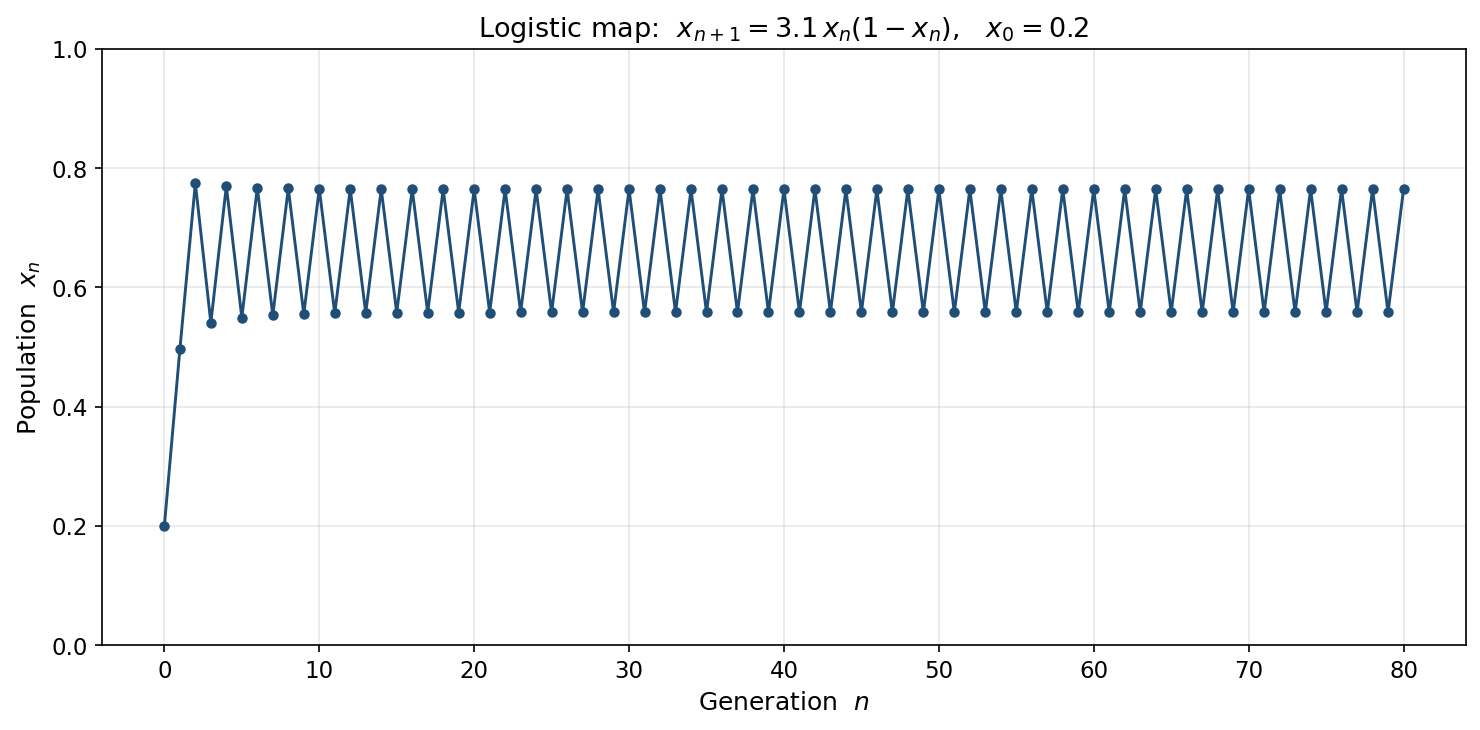

In [43]:
# ---- change these values to follow a different population ----
r  = 3.1
x0 = 0.2
n_steps = 80
# -------------------------------------------------------------

x = logistic_map(r, x0, n_steps)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(range(n_steps + 1), x, marker='o', markersize=4,
        linewidth=1.4, color='#1f4e79')

ax.set_xlabel('Generation  $n$')
ax.set_ylabel('Population  $x_n$')
ax.set_title(f'Logistic map:  $x_{{n+1}} = {r}\\,x_n(1 - x_n)$,   $x_0 = {x0}$')
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('logistic_time_series.png', dpi=300, bbox_inches='tight')
plt.show()

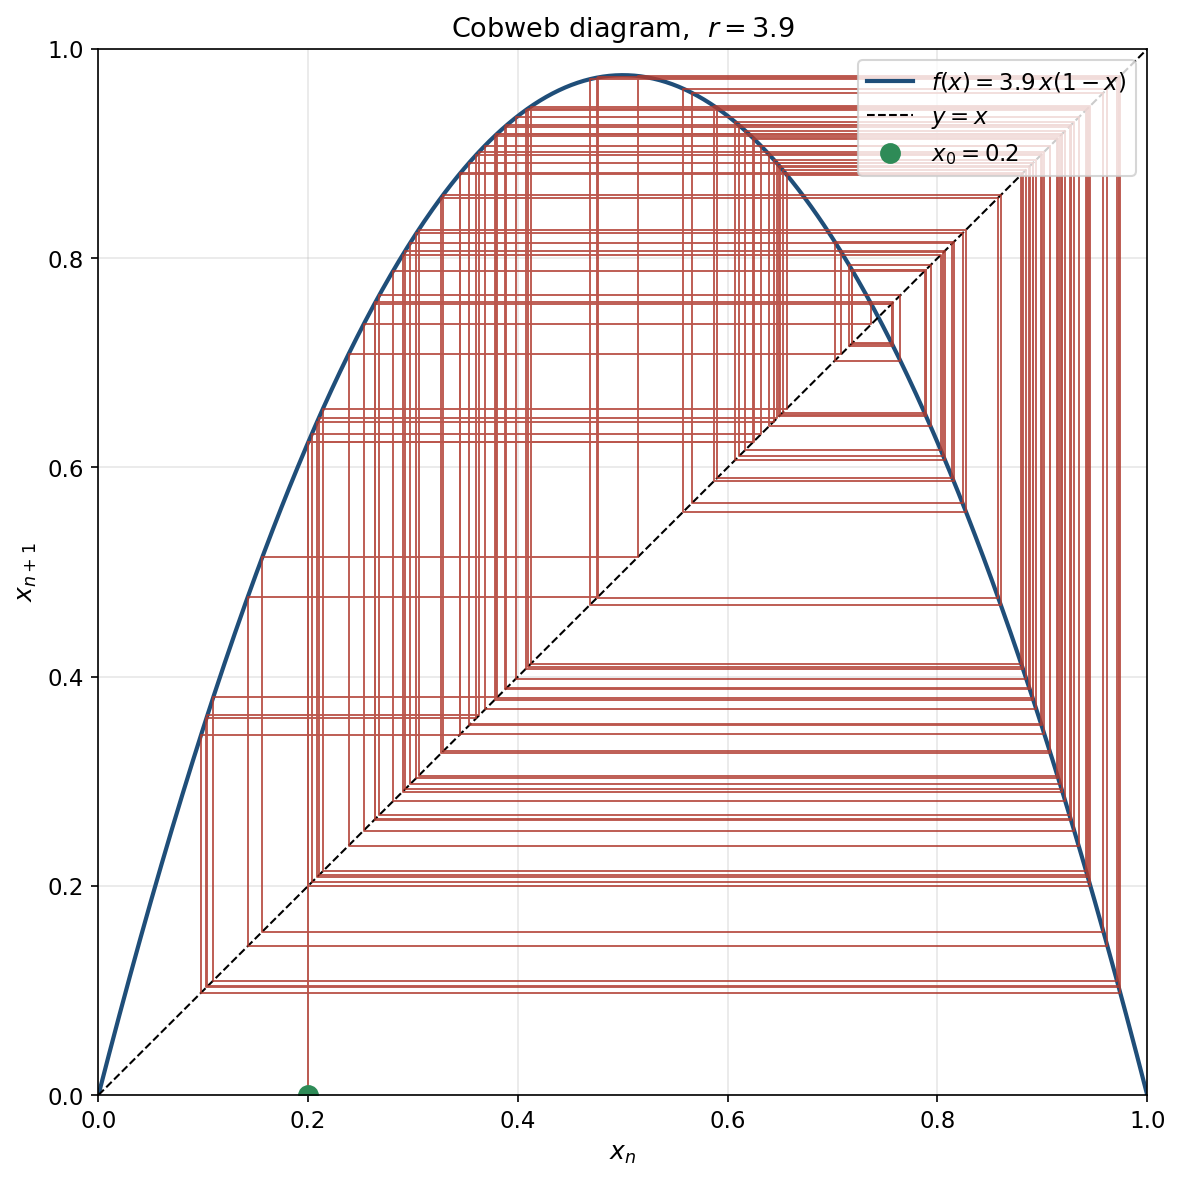

In [39]:
# ---- change r and x0 here ----
r  = 3.9
x0 = 0.2
n_iter = 120
# ------------------------------

def logistic(x, r):
    return r * x * (1.0 - x)

fig, ax = plt.subplots(figsize=(8, 8))

x_grid = np.linspace(0, 1, 500)
ax.plot(x_grid, logistic(x_grid, r), color='#1f4e79', linewidth=2.0,
        label=f'$f(x) = {r}\\,x(1 - x)$')
ax.plot([0, 1], [0, 1], 'k--', linewidth=1.0, label='$y = x$')

x = x0
xs, ys = [x], [0.0]
for _ in range(n_iter):
    y = logistic(x, r)
    xs.extend([x, y])
    ys.extend([y, y])
    x = y
ax.plot(xs, ys, color='#b03a2e', linewidth=0.9, alpha=0.85)

ax.plot(x0, 0, 'o', color='#2e8b57', markersize=9, label=f'$x_0 = {x0}$')

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel('$x_n$')
ax.set_ylabel('$x_{n+1}$')
ax.set_title(f'Cobweb diagram,  $r = {r}$')
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig('cobweb.png', dpi=300, bbox_inches='tight')
plt.show()

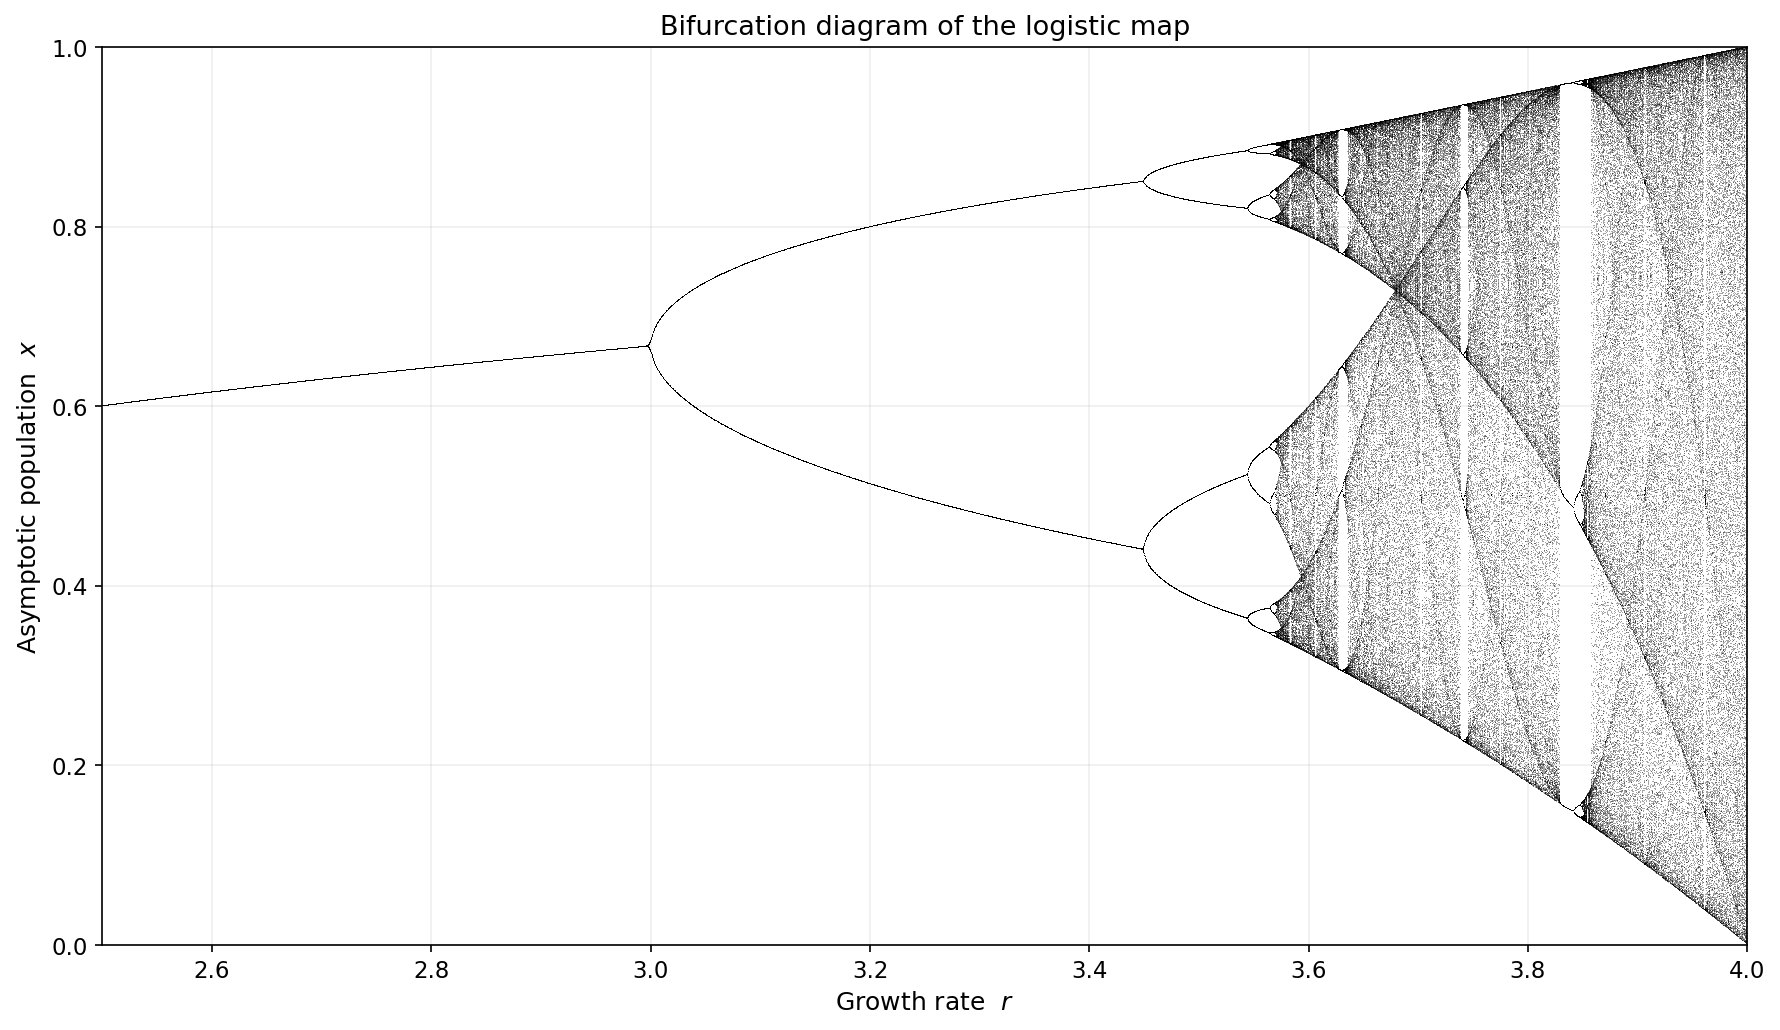

In [40]:
n_transient = 1000
n_keep      = 200
r_min, r_max = 2.5, 4.0
n_r         = 4000
x0          = 0.5

r_values = np.linspace(r_min, r_max, n_r)
r_plot   = np.empty(n_r * n_keep)
x_plot   = np.empty(n_r * n_keep)

k = 0
for r in r_values:
    x = x0
    for _ in range(n_transient):
        x = r * x * (1.0 - x)
    for _ in range(n_keep):
        x = r * x * (1.0 - x)
        r_plot[k] = r
        x_plot[k] = x
        k += 1

fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(r_plot, x_plot, ',', color='black', alpha=0.35)

ax.set_xlabel('Growth rate  $r$')
ax.set_ylabel('Asymptotic population  $x$')
ax.set_title('Bifurcation diagram of the logistic map')
ax.set_xlim(r_min, r_max)
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.savefig('bifurcation.png', dpi=300, bbox_inches='tight')
plt.show()

The two cycle points:
  x_1 = 0.513045
  x_2 = 0.799455


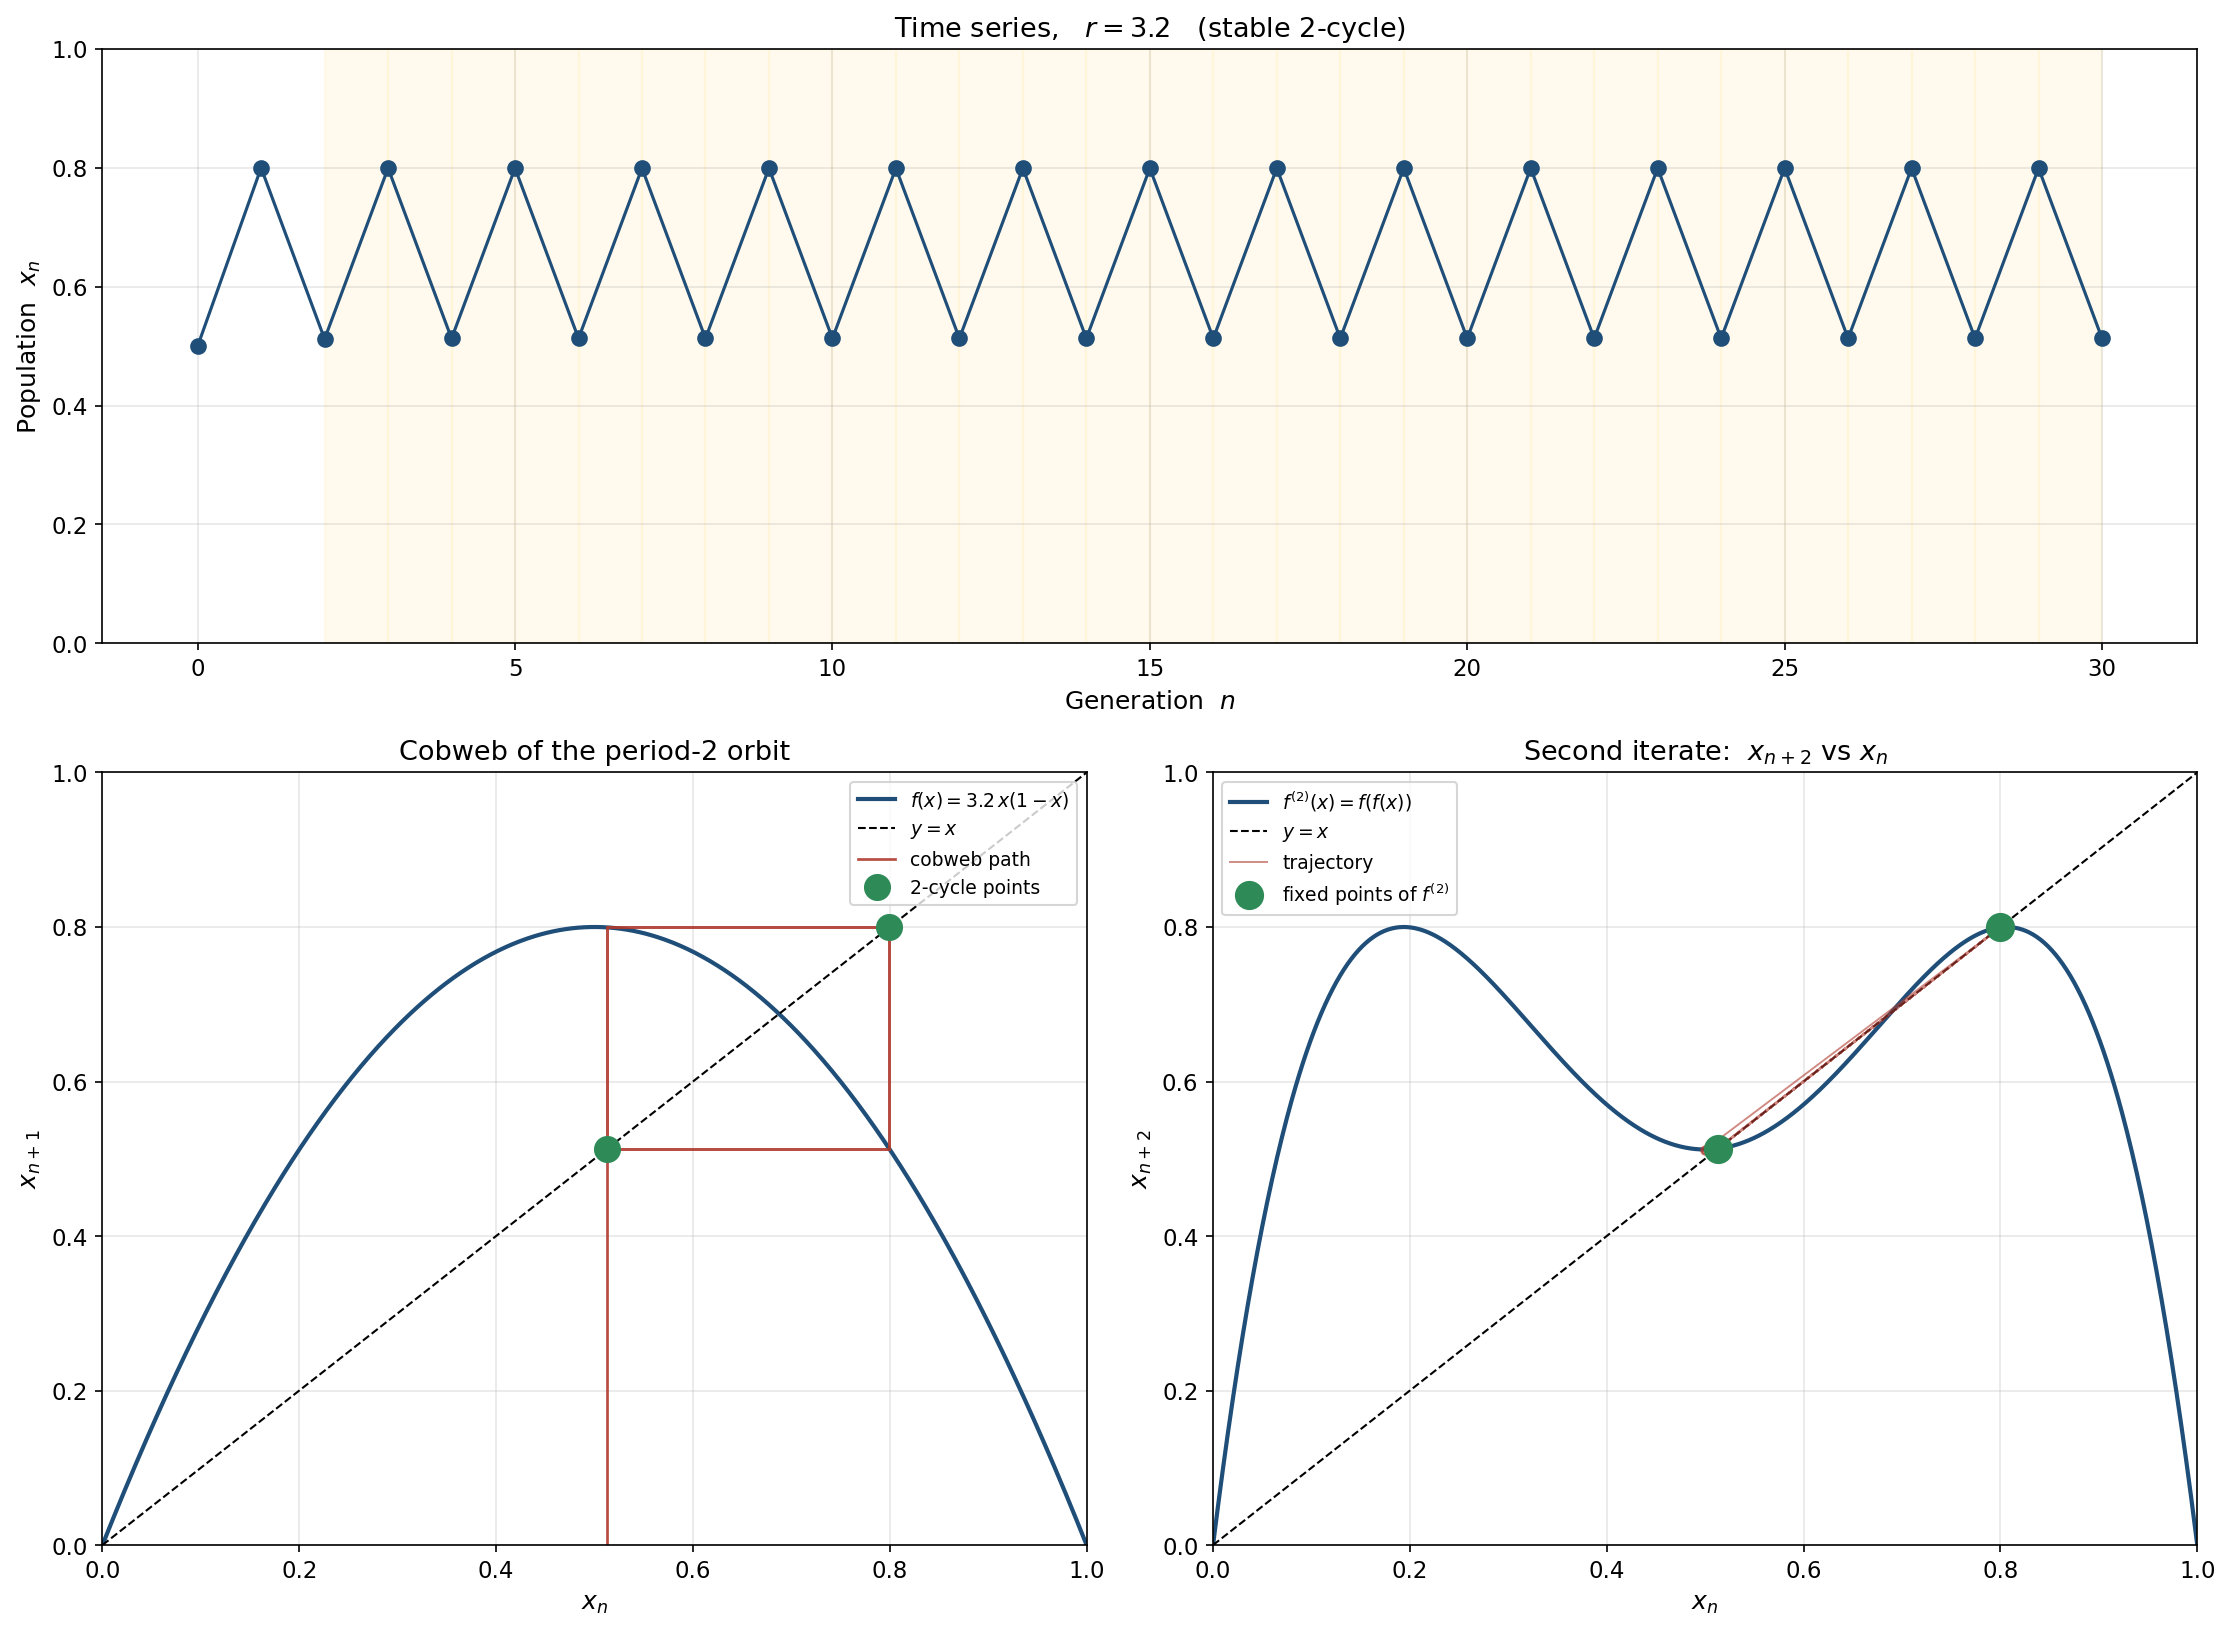

In [45]:
# ---- period-2 window of the logistic map ----
r  = 3.2                # inside the stable 2-cycle window
x0 = 0.5
n_steps = 60
# ---------------------------------------------

def f(x, r):
    return r * x * (1.0 - x)

# ---- time series ----
x = logistic_map(r, x0, n_steps)

# ---- locate the two points of the stable 2-cycle ----
x_cycle = np.sort(x[-2:])
print("The two cycle points:")
for i, xc in enumerate(x_cycle, 1):
    print(f"  x_{i} = {xc:.6f}")

# ---- iterate maps ----
x_grid = np.linspace(0, 1, 800)
f1 = f(x_grid, r)
f2 = f(f(x_grid, r), r)

# ---- figure with three panels ----
fig = plt.figure(figsize=(15, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.3])

# ---------------- Top: time series (spans both columns) ----------------
ax = fig.add_subplot(gs[0, :])
n_show = 30
ax.plot(range(n_show + 1), x[:n_show + 1],
        marker='o', markersize=7, linewidth=1.5, color='#1f4e79')
for k in range(2, n_show):
    ax.axvspan(k, k + 1, color='#fff2cc', alpha=0.35, zorder=0)
ax.set_xlabel('Generation  $n$')
ax.set_ylabel('Population  $x_n$')
ax.set_title(f'Time series,   $r = {r}$   (stable 2-cycle)')
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)

# ---------------- Bottom left: cobweb ----------------
ax = fig.add_subplot(gs[1, 0])
ax.plot(x_grid, f1, color='#1f4e79', linewidth=2.0,
        label=f'$f(x) = {r}\\,x(1-x)$')
ax.plot([0, 1], [0, 1], 'k--', linewidth=1.0, label='$y = x$')

x_tmp = x0
for _ in range(200):
    x_tmp = f(x_tmp, r)
xs, ys = [x_tmp], [0.0]
for _ in range(6):
    y = f(x_tmp, r)
    xs.extend([x_tmp, y])
    ys.extend([y, y])
    x_tmp = y
ax.plot(xs, ys, color='#b03a2e', linewidth=1.3, alpha=0.9, label='cobweb path')
ax.plot(x_cycle, x_cycle, 'o', color='#2e8b57',
        markersize=12, zorder=5, label='2-cycle points')
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel('$x_n$'); ax.set_ylabel('$x_{n+1}$')
ax.set_title('Cobweb of the period-2 orbit')
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right', fontsize=9)

# ---------------- Bottom right: x_{n+2} vs x_n ----------------
ax = fig.add_subplot(gs[1, 1])
ax.plot(x_grid, f2, color='#1f4e79', linewidth=2.0,
        label='$f^{(2)}(x) = f(f(x))$')
ax.plot([0, 1], [0, 1], 'k--', linewidth=1.0, label='$y = x$')

# trajectory in (x_n, x_{n+2}) coordinates
ax.plot(x[:-2], x[2:], '-', color='#b03a2e', linewidth=0.9,
        alpha=0.6, label='trajectory')
ax.plot(x[:-2], x[2:], 'o', color='#b03a2e', markersize=4, alpha=0.7)

# highlight the fixed points of f^(2): the two cycle points + the two f-fixed points
ax.plot(x_cycle, x_cycle, 'o', color='#2e8b57',
        markersize=13, zorder=6, label='fixed points of $f^{(2)}$')

ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel('$x_n$'); ax.set_ylabel('$x_{n+2}$')
ax.set_title('Second iterate:  $x_{n+2}$ vs $x_n$')
ax.grid(True, alpha=0.3)
ax.legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.savefig('period2_cycle.png', dpi=300, bbox_inches='tight')
plt.show()

The three cycle points:
  x_1 = 0.159481
  x_2 = 0.513188
  x_3 = 0.956446


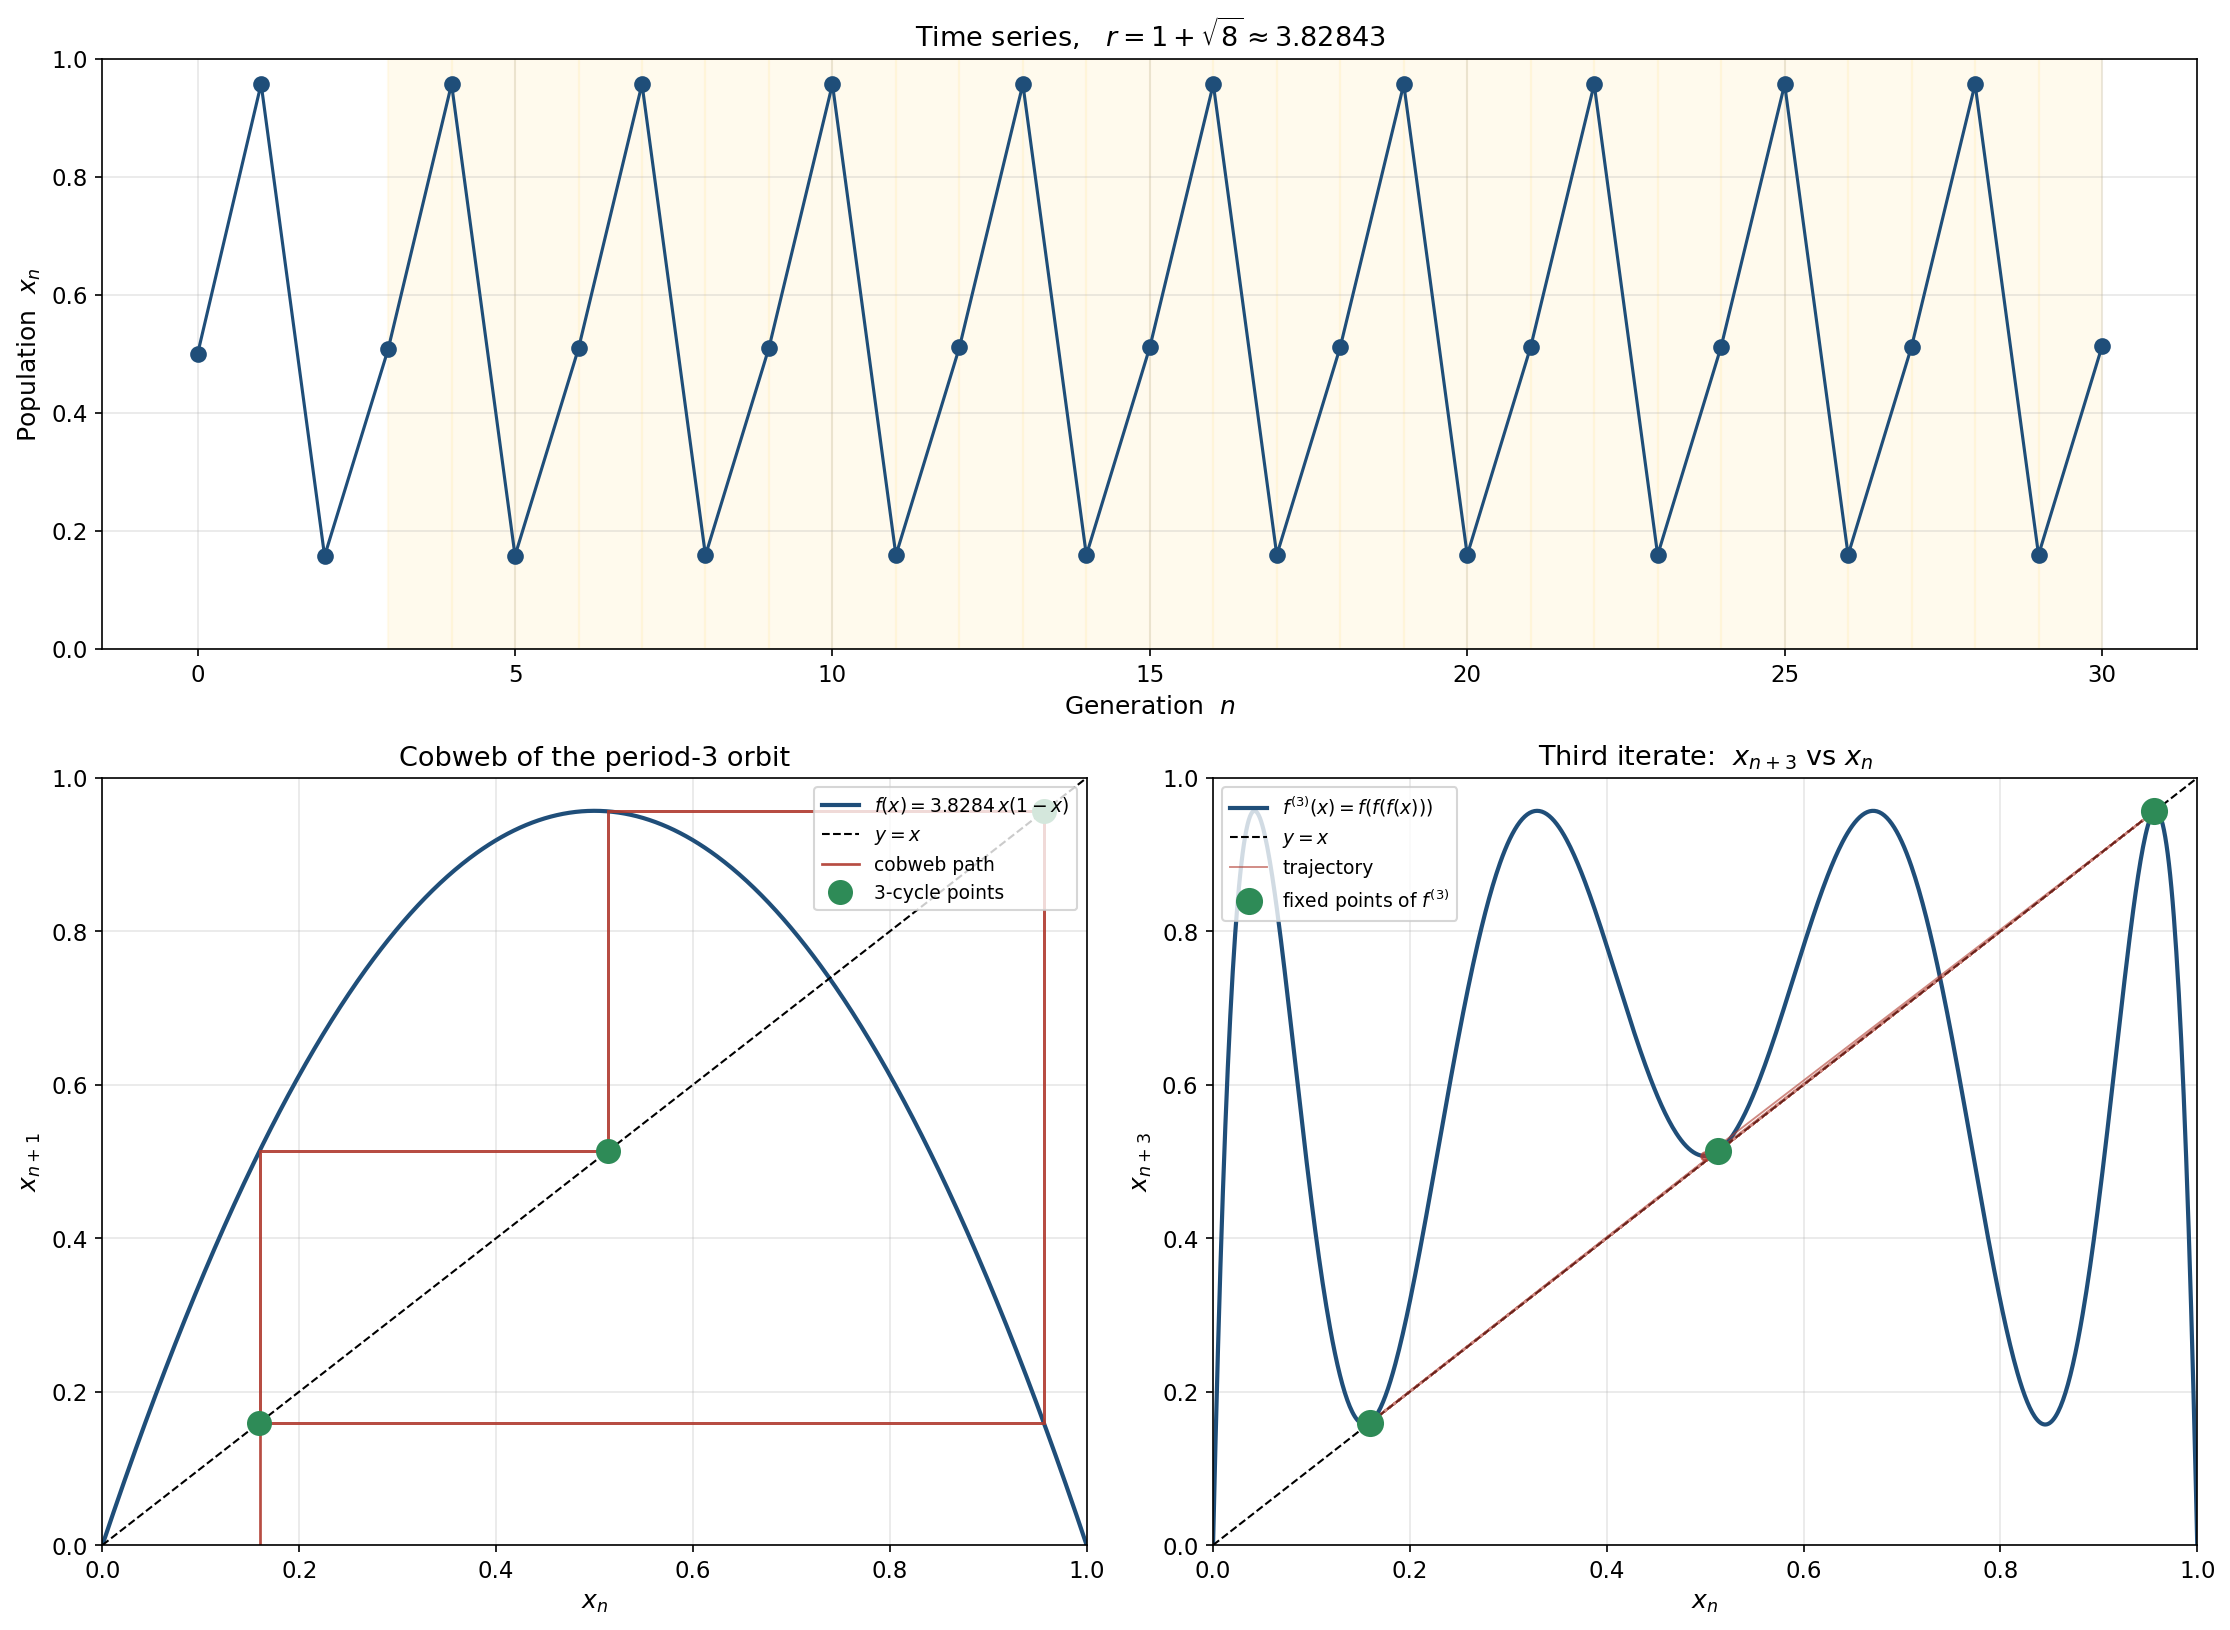

In [42]:
# ---- period-3 window of the logistic map ----
r  = 1 + np.sqrt(8)     # onset of the 3-cycle:  r ≈ 3.8284271
x0 = 0.5
n_steps = 60
# ---------------------------------------------

def f(x, r):
    return r * x * (1.0 - x)

# ---- time series ----
x = logistic_map(r, x0, n_steps)

# ---- locate the three points of the stable 3-cycle ----
x_cycle = np.sort(x[-3:])
print("The three cycle points:")
for i, xc in enumerate(x_cycle, 1):
    print(f"  x_{i} = {xc:.6f}")

# ---- iterate maps ----
x_grid = np.linspace(0, 1, 800)
f1 = f(x_grid, r)
f3 = f(f(f(x_grid, r), r), r)

# ---- figure with three panels ----
fig = plt.figure(figsize=(15, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.3])

# ---------------- Top: time series (spans both columns) ----------------
ax = fig.add_subplot(gs[0, :])
n_show = 30
ax.plot(range(n_show + 1), x[:n_show + 1],
        marker='o', markersize=7, linewidth=1.5, color='#1f4e79')
for k in range(3, n_show):
    ax.axvspan(k, k + 1, color='#fff2cc', alpha=0.35, zorder=0)
ax.set_xlabel('Generation  $n$')
ax.set_ylabel('Population  $x_n$')
ax.set_title(f'Time series,   $r = 1 + \\sqrt{{8}} \\approx {r:.5f}$')
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)

# ---------------- Bottom left: cobweb ----------------
ax = fig.add_subplot(gs[1, 0])
ax.plot(x_grid, f1, color='#1f4e79', linewidth=2.0,
        label=f'$f(x) = {r:.4f}\\,x(1-x)$')
ax.plot([0, 1], [0, 1], 'k--', linewidth=1.0, label='$y = x$')

x_tmp = x0
for _ in range(200):
    x_tmp = f(x_tmp, r)
xs, ys = [x_tmp], [0.0]
for _ in range(9):
    y = f(x_tmp, r)
    xs.extend([x_tmp, y])
    ys.extend([y, y])
    x_tmp = y
ax.plot(xs, ys, color='#b03a2e', linewidth=1.3, alpha=0.9, label='cobweb path')
ax.plot(x_cycle, x_cycle, 'o', color='#2e8b57',
        markersize=11, zorder=5, label='3-cycle points')
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel('$x_n$'); ax.set_ylabel('$x_{n+1}$')
ax.set_title('Cobweb of the period-3 orbit')
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right', fontsize=9)

# ---------------- Bottom right: x_{n+3} vs x_n ----------------
ax = fig.add_subplot(gs[1, 1])
ax.plot(x_grid, f3, color='#1f4e79', linewidth=2.0,
        label='$f^{(3)}(x) = f(f(f(x)))$')
ax.plot([0, 1], [0, 1], 'k--', linewidth=1.0, label='$y = x$')

# trajectory in (x_n, x_{n+3}) coordinates
ax.plot(x[:-3], x[3:], '-', color='#b03a2e', linewidth=0.9,
        alpha=0.6, label='trajectory')
ax.plot(x[:-3], x[3:], 'o', color='#b03a2e', markersize=4, alpha=0.7)

# highlight the three intersections f^(3)(x) = x
ax.plot(x_cycle, x_cycle, 'o', color='#2e8b57',
        markersize=12, zorder=6, label='fixed points of $f^{(3)}$')

ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel('$x_n$'); ax.set_ylabel('$x_{n+3}$')
ax.set_title('Third iterate:  $x_{n+3}$ vs $x_n$')
ax.grid(True, alpha=0.3)
ax.legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.savefig('period3_cycle.png', dpi=300, bbox_inches='tight')
plt.show()